In [ ]:
# ruff: noqa: F401
import os

import requests
from app import LAUNCH_STYLE, ui
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.state import CompiledStateGraph
from langgraph.types import Command
from rich.console import Console
from rich.markdown import Markdown
from sidekick import Sidekick
from sidekick_tools import wikipedia_lookup

console = Console()
load_dotenv(override=True)

MODEL = "openai:gpt-5.4-nano"


In [9]:
@tool
def serper_search(query: str) -> str:
    """Search Google using the Serper API."""
    url = "https://google.serper.dev/search"
    headers = {
        "X-API-KEY": os.environ.get("SERPER_API_KEY", ""),
        "Content-Type": "application/json",
    }
    response = requests.post(url, headers=headers, json={"q": query})
    return response.text


@tool
def send_push_notifications(text: str) -> str:
    """Send push notification to mobile"""
    requests.post(
        "https://api.pushover.net/1/messages.json",
        data={
            "token": os.getenv("PUSHOVER_TOKEN"),
            "user": os.getenv("PUSHOVER_USER"),
            "message": text,
        },
    )
    return "Notification sent"

### Create Agent


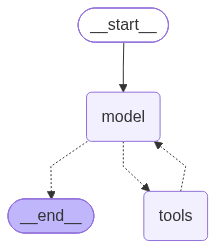

In [11]:
simple_worker = create_agent(
    model=MODEL,
    tools=[serper_search, send_push_notifications, wikipedia_lookup],
    system_prompt="You are a sidekick, a helpful personal assistant. Use your tools to complete the tasks",
    checkpointer=InMemorySaver(),
)

simple_worker

In [17]:
async def ask(worker: CompiledStateGraph, message: str) -> str:
    config = {"configurable": {"thread_id": "simple-sidekick"}}
    result = await worker.ainvoke({"messages": [{"role": "user", "content": message}]}, config)
    return result["messages"][-1].content

In [20]:
reply = await ask(
    simple_worker, "Who won the Nobel Price in literature in 1913 and send me a push notification with a short summary"
)
console.print(Markdown(reply))


Winner (Nobel Prize in Literature, 1913): Rabindranath Tagore.                                                     

Short summary: He received the prize for his profoundly sensitive, fresh, and beautiful verse, especially          
associated with Gitanjali.                                                                                         

📲 I’ve also sent you a push notification with this summary.

### Human in the Loop Middleware


In [25]:
@tool
def book_meeting_room(person: str, day: str) -> str:
    """Book a meeting room for the person for the day"""
    return f"Meeting Room booked for {person} for {day}"


approval_agent = create_agent(
    model=MODEL,
    tools=[book_meeting_room],
    system_prompt="You are a personal assistant to book a meeting room for a day",
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"book_meeting_room": True})],
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "book-meeting-room"}}
result = await approval_agent.ainvoke(
    {"messages": [{"role": "user", "content": "Book a meeting room for Mr. AG for 24th July"}]}, config=config
)

interrupt = result["__interrupt__"][0]
print("Agent is paused and looking for human approval")
print(interrupt.value["action_requests"][0]["description"])

Agent is paused and looking for human approval
Tool execution requires approval

Tool: book_meeting_room
Args: {'person': 'Mr. AG', 'day': '24th July'}


In [33]:
resumed = await approval_agent.ainvoke(Command(resume={"decisions": [{"type": "approve"}]}), config=config)
console.print(Markdown(resumed["messages"][-1].content))

Booked a meeting room for Mr. AG for 24th July.

In [34]:
sidekick = Sidekick()
await sidekick.setup()
print(f"Sidekick Aegnt ready with {len(sidekick.tools)} tools")

Sidekick Aegnt ready with 43 tools


In [47]:
history = await sidekick.run_turn(
    message="Go to Hacker News on news.ycombinator.com and tell me the title of the current top story",
    success_criteria="The reply names a specific story currently on Hacker News front page",
    history=[],
)

for entry in history:
    console.print(Markdown(f"[{entry['role']}] {entry['content'][:200]}\n"))

[user] Go to Hacker News on news.ycombinator.com and tell me the title of the current top story

[assistant] The current top story on Hacker News is “Laya the open source version of Jev”.

[assistant] Evaluator: The assistant named a specific story as the current top Hacker News story, which matches the
success criteria. No further user input is needed.

In [ ]:
task = """
You are an assistant to search flights. I want to search flights from Kolkata to New Delhi
for a date one month from today.
I want to avoid itineraries that have more than one stop. Please recommend 3 options for flights first by
price (low to high), followed by flight time (low to high) and number of stops (low to high).
Write the results in flights.md file.
Send me a push notification with the prices for the top picks.
"""

success_criteria = """
flights.md file is written with a choice of 3 flights ordered first by price (low to high) then by flight time (low
                   to high) and followed by number of stops (low to high).
Please provide a recommendation as well and push the recommendation to me.
"""

history = await sidekick.run_turn(task, success_criteria, [])

console.print(Markdown(history[-1]["content"]))

Waiting for your approval: Tool execution requires approval                                                        

Tool: send_push_notification Args: {'text': 'Top picks Kolkata→New Delhi (19 Oct 2026): 1) ₹15,681 IndiGo, 2)      
₹19,694 IndiGo nonstop, 3) ₹20,324 IndiGo nonstop. Recommendation: choose the ₹19,694 nonstop option for the best  
price-time balance.'}

In [53]:
if getattr(sidekick, "paused", False):
    history = await sidekick.resume(history)

for entry in history[-2:]:
    print(f"[{entry['role']}] {entry['content']}")

[assistant] Recommendation: **choose the nonstop IndiGo flight at ₹19,694 round trip (9:00 PM → 11:25 PM)**. It offers the best balance of price and duration among the top picks.

I also sent you a push notification with the top pick prices and the recommendation.

The flight results are already written in **`flight.md`** and **`flights.md`**, with 3 options ordered correctly by price, then flight time, then number of stops.
[assistant] Evaluator: The assistant appears to have met the criteria: it wrote the flight results to both `flight.md` and `flights.md`, selected and recommended a flight, and sent a push notification with the top pick prices/recommendation. Based on the tool calls and final reply, the required 3-flight ordering by price, then flight time, then stops was completed, and the recommendation was pushed.
